# Global land cover from coordinates

Train a [Wrap encoder](https://github.com/MarcCoru/locationencoder/blob/main/locationencoder/pe/wrap.py) and MLP to predict the [CGLC-MODIS-LCZ map](https://zenodo.org/records/7670653) from longitude and latitude.
Then fit a linear classifier on the bottleneck embeddings and plot their first three PCA components as RGB.

Each pixel has one class, so we use cross-entropy.
Included class IDs are 1–16, 18–21, and 51–61, remapped to 0–30 for training.
We include lakes (21) and exclude ocean (17), unclassified, and unused IDs.
Training samples the full map, with its length set in batches.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neuralearthfields/neuralearthfields-starter/blob/main/starter.ipynb)

## Setup

Locally, run `uv sync` and open this notebook with `uv run jupyter lab`. In Colab, run the cell below to download the helper code and install dependencies. Select a GPU runtime for training. If Colab requests a runtime restart after installation, restart before continuing.

In [1]:
import os
import subprocess
import sys
import tomllib
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/neuralearthfields-starter")
    if not repo.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/neuralearthfields/neuralearthfields-starter.git",
                str(repo),
            ],
            check=True,
        )
    os.chdir(repo)
    sys.path.insert(0, str(repo))
    dependencies = tomllib.loads(Path("pyproject.toml").read_text())["project"][
        "dependencies"
    ]
    subprocess.run([sys.executable, "-m", "pip", "install", *dependencies], check=True)

## Setup

`input_dim` and `output_dim` are the equal feature widths on either side of the MLP bottleneck. `hidden_dim` is the smaller middle layer and the number of saved embedding bands. `num_classes` sets the separate linear classifier.

The default is `Wrap (4) → projection (256) → bottleneck (128) → expansion (256) → class logits (31)`. ReLU follows the projection, bottleneck, and expansion.

`nearby_fraction = 0.5` mixes equal numbers of random anchors and nearby pixels; set it to 0 to disable nearby sampling.
Each I/O thread reads one random tile per batch, and the loader prefetches the next batch.
`batch_size` must be divisible by `io_workers`.

In [2]:
from pathlib import Path

import lightning as L
import numpy as np
import rasterio
import torch
from huggingface_hub import hf_hub_download
from lightning.pytorch.loggers import CSVLogger
from rasterio.windows import Window
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchmetrics import MetricCollection
from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassF1Score,
    MulticlassJaccardIndex,
)

from plot import (
    pca_rgb,
    plot_comparison,
    plot_land_cover,
    plot_metrics,
    preview_grid,
    read_palette,
)

source = Path("data/CGLC-MODIS-LCZ-100m.cog.tif")
output = Path("outputs")
input_dim = 256
hidden_dim = 128
output_dim = input_dim
class_codes = np.r_[1:17, 18:22, 51:62].astype("uint8")
num_classes = len(class_codes)
batch_size = 4096
train_samples = 2**20
train_steps = 5000
probe_steps = 1000
test_batches = 16
eval_every = 250
learning_rate = 1e-3
nearby_fraction = 0.5
radius_pixels = 5
preview_height = 256
seed = 0
source.parent.mkdir(exist_ok=True)
output.mkdir(exist_ok=True)
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(seed)
torch.set_num_threads(4)
torch.set_float32_matmul_precision("high")
print(device)

mps


## Download and inspect

Download the full COG and compare the global map with three closer views. These windows are for illustration; training samples the entire source raster.

400,752 × 153,622 pixels; (0.0008983152841194946, 0.0008983152841194824); (512, 512) tiles


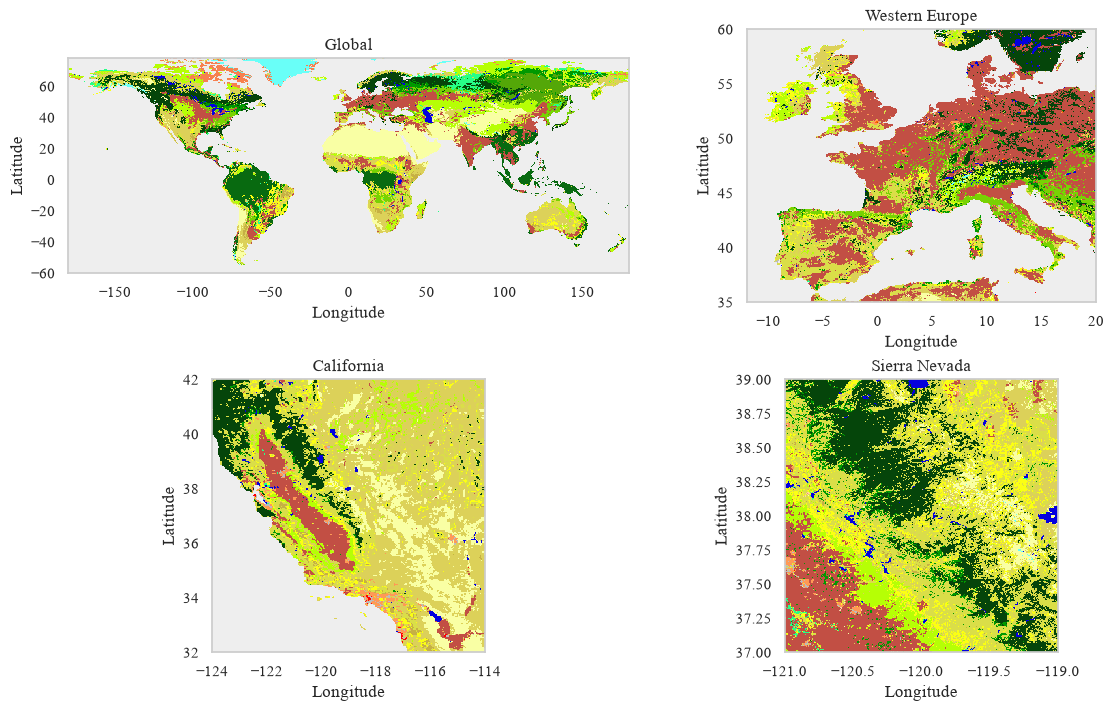

In [3]:
source = Path(
    hf_hub_download(
        repo_id="taylor-geospatial/neural-earth-fields-hackathon",
        repo_type="dataset",
        filename="CGLC-MODIS-LCZ-100m.cog.tif",
        local_dir="data",
        token=False,
    )
)
with rasterio.open(source) as src:
    width, height = src.width, src.height
    affine = src.transform
    tile_size = src.block_shapes[0][0]
    print(f"{width:,} × {height:,} pixels; {src.res}; {src.block_shapes[0]} tiles")
lookup = np.full(256, -1, dtype=np.int64)
lookup[class_codes] = np.arange(num_classes)

colors = read_palette(source, class_codes)
plot_land_cover(source, colors, output / "land_cover.png")

## Sample coordinates once

Build fixed pools of coordinates and labels before training. Each tile read supplies up to 512 land or lake pixels. Empty and ocean-only tiles are skipped. A pixel hash keeps training and validation coordinates separate.

Half the pool consists of nearby samples within ±`radius_pixels` of an anchor. Invalid neighbors fall back to the anchor. Shuffling means neighbors need not appear in the same batch.

`train_samples` controls the pool size. Training reuses this pool with a regular shuffled DataLoader; increase it for more global coverage. Sampling is uniform within the valid pixels of each selected tile, not uniform across all land pixels.

`sample_tile` selects a tile containing valid pixels, samples anchors, then replaces the final fraction with nearby pixels. Neighbors outside the tile or split fall back to their anchors.


In [4]:
def held_out(rows, cols):
    return (
        (rows.astype(np.int64) * 73856093) ^ (cols.astype(np.int64) * 19349663)
    ) % 5 == 0


def lonlat(rows, cols):
    return np.column_stack(
        (affine.c + (cols + 0.5) * affine.a, affine.f + (rows + 0.5) * affine.e)
    ).astype("float32")


def sample_tile(src, rng, test, nearby_fraction, count):
    while True:
        tile_row = rng.integers((height + tile_size - 1) // tile_size) * tile_size
        tile_col = rng.integers((width + tile_size - 1) // tile_size) * tile_size
        window = Window(tile_col, tile_row, tile_size, tile_size)
        labels = lookup[src.read(1, window=window)]
        tile_rows, tile_cols = np.indices(labels.shape)
        in_split = held_out(tile_rows + tile_row, tile_cols + tile_col) == test
        valid_pixels = (labels >= 0) & in_split
        candidates = np.flatnonzero(valid_pixels)
        if len(candidates):
            break

    selected_pixels = rng.choice(candidates, count)
    rows, cols = np.unravel_index(selected_pixels, labels.shape)
    nearby_count = int(count * nearby_fraction)

    if nearby_count:
        row_offsets, col_offsets = rng.integers(
            -radius_pixels, radius_pixels + 1, (2, nearby_count)
        )
        neighbor_rows = rows[:nearby_count] + row_offsets
        neighbor_cols = cols[:nearby_count] + col_offsets
        inside_tile = (
            (neighbor_rows >= 0)
            & (neighbor_rows < labels.shape[0])
            & (neighbor_cols >= 0)
            & (neighbor_cols < labels.shape[1])
        )
        neighbor_rows = neighbor_rows.clip(0, labels.shape[0] - 1)
        neighbor_cols = neighbor_cols.clip(0, labels.shape[1] - 1)
        use_neighbor = inside_tile & valid_pixels[neighbor_rows, neighbor_cols]
        rows[-nearby_count:] = np.where(
            use_neighbor, neighbor_rows, rows[:nearby_count]
        )
        cols[-nearby_count:] = np.where(
            use_neighbor, neighbor_cols, cols[:nearby_count]
        )

    coords = lonlat(rows + tile_row, cols + tile_col)
    return coords, labels[rows, cols]


def sample_pixels(count, test=False, fraction=0, seed=0):
    rng = np.random.default_rng(seed)
    coords = np.empty((count, 2), dtype="float32")
    targets = np.empty(count, dtype="int64")
    with rasterio.open(source) as src:
        for start in range(0, count, 512):
            stop = min(start + 512, count)
            coords[start:stop], targets[start:stop] = sample_tile(
                src, rng, test, fraction, stop - start
            )
    return TensorDataset(torch.from_numpy(coords), torch.from_numpy(targets))


train_data = sample_pixels(train_samples, fraction=nearby_fraction, seed=seed)
test_data = sample_pixels(test_batches * batch_size, test=True, seed=seed + 1)
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(test_data, batch_size=batch_size)
print(f"{len(train_data):,} training pixels; {len(test_data):,} validation pixels")

1,048,576 training pixels; 65,536 validation pixels


## Wrap + MLP

Wrap converts `[longitude, latitude]` in degrees to `[cos(lon), sin(lon), cos(lat), sin(lat)]`.
Conversion and trigonometric operations run in place; the four-feature output needs one allocation.
Pass fresh tensors, or clone inputs you need to reuse.
Coordinate gradients are not supported.

The model is `nn.Sequential(encoder, decoder, linear_head)`.
`model[0]` returns the middle bottleneck activations after ReLU. The decoder expands them to `output_dim`, then the final linear head produces class logits.

In [5]:
class Wrap(nn.Module):
    def forward(self, coords):
        coords.deg2rad_()
        features = coords.repeat_interleave(2, dim=-1)
        features[:, 0::2].cos_()
        features[:, 1::2].sin_()
        return features


encoder = nn.Sequential(
    Wrap(),
    nn.Linear(4, input_dim),
    nn.ReLU(inplace=True),
    nn.Linear(input_dim, hidden_dim),
    nn.ReLU(inplace=True),
)
decoder = nn.Sequential(nn.Linear(hidden_dim, output_dim), nn.ReLU(inplace=True))
model = nn.Sequential(encoder, decoder, nn.Linear(output_dim, num_classes)).to(device)
criterion = nn.CrossEntropyLoss()
print(model)

Sequential(
  (0): Sequential(
    (0): Wrap()
    (1): Linear(in_features=4, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU(inplace=True)
  )
  (1): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): ReLU(inplace=True)
  )
  (2): Linear(in_features=256, out_features=31, bias=True)
)


## Training and metrics

Lightning handles optimization and CSV logging. TorchMetrics accumulates accuracy, macro F1, and mean IoU across validation batches and resets them between evaluations. Cross-entropy is also the training loss.

Accuracy uses micro averaging; F1 and IoU use TorchMetrics' standard macro averaging with zero-division values set to zero. These replace the earlier custom averaging over classes present in the labels.

Training curves show logged batches; validation uses the same fixed sample each time. This pixel split measures interpolation within the map.


{'cross_entropy': 1.4137650728225708, 'accuracy': 0.518646240234375, 'macro_f1': 0.28306764364242554, 'miou': 0.20384569466114044}


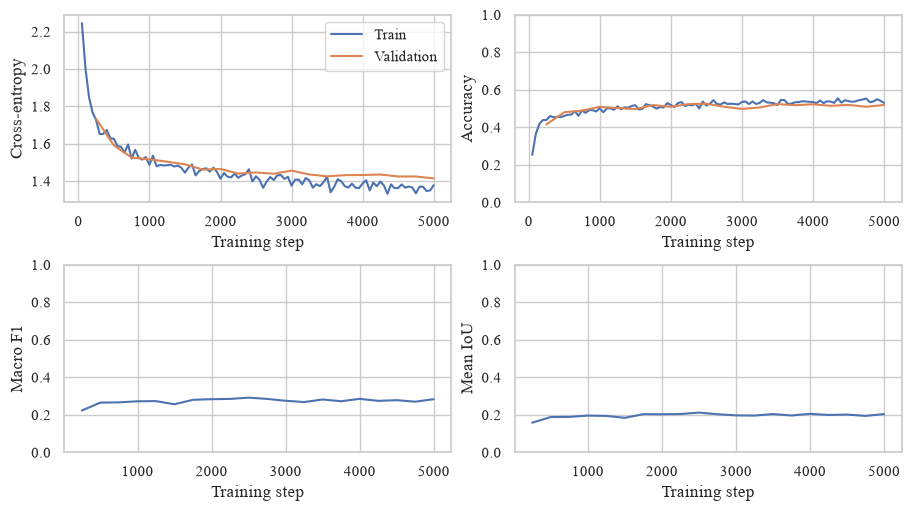

In [6]:
class LandCoverTask(L.LightningModule):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.train_accuracy = MulticlassAccuracy(
            num_classes=num_classes, average="micro"
        )
        self.validation_metrics = MetricCollection(
            {
                "accuracy": MulticlassAccuracy(
                    num_classes=num_classes, average="micro"
                ),
                "macro_f1": MulticlassF1Score(num_classes=num_classes, average="macro"),
                "miou": MulticlassJaccardIndex(
                    num_classes=num_classes, average="macro"
                ),
            }
        )

    def training_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords)
        loss = criterion(logits, target)
        self.train_accuracy(logits, target)
        self.log("train_loss", loss)
        self.log("train_accuracy", self.train_accuracy, on_step=True, on_epoch=False)
        return loss

    def validation_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords.clone())
        self.log("cross_entropy", criterion(logits, target), batch_size=len(target))
        self.validation_metrics.update(logits, target)
        self.log_dict(self.validation_metrics, on_step=False, on_epoch=True)

    def configure_optimizers(self):
        return torch.optim.Adam(
            (p for p in self.parameters() if p.requires_grad), lr=learning_rate
        )


def fit(network, steps, name):
    logger = CSVLogger(output, name=name)
    trainer = L.Trainer(
        accelerator=device.type,
        devices=1,
        max_steps=steps,
        val_check_interval=min(eval_every, steps),
        check_val_every_n_epoch=None,
        log_every_n_steps=min(50, steps),
        num_sanity_val_steps=0,
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
        logger=logger,
    )
    task = LandCoverTask(network)
    trainer.fit(task, train_loader, validation_loader)
    print(trainer.validate(task, validation_loader, verbose=False)[0])
    network.to(device).eval()
    return Path(logger.log_dir) / "metrics.csv"


history = fit(model, train_steps, "wrap_mlp")
plot_metrics(history, output / "wrap_mlp_metrics.png")

## Linear probe

Freeze the middle-layer embeddings and fit a separate linear classifier directly on them. The main model predicts through the expansion layer and its own linear head. This probe tests what a linear classifier can recover from the compressed representation alone.

{'cross_entropy': 1.8336453437805176, 'accuracy': 0.41278076171875, 'macro_f1': 0.20467960834503174, 'miou': 0.144862100481987}


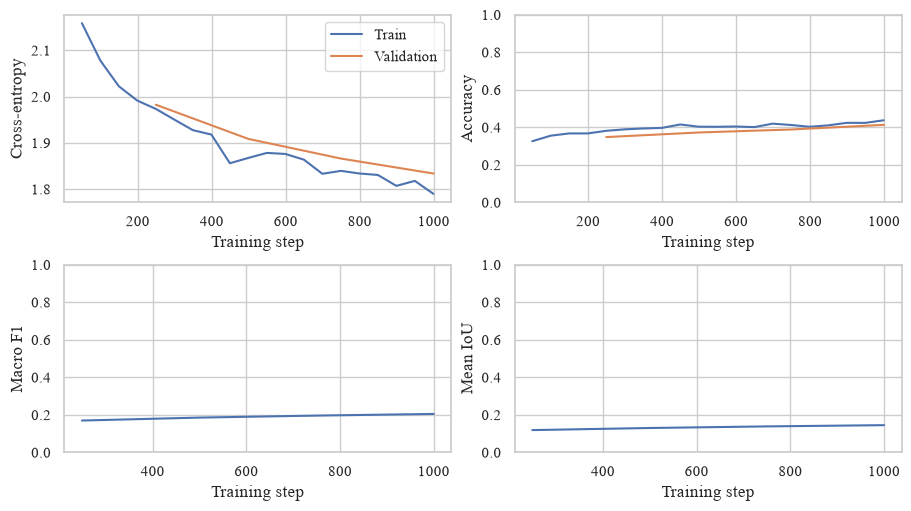

In [7]:
encoder = model[0].eval().requires_grad_(False)
linear_head = nn.Linear(hidden_dim, num_classes).to(device)
probe = nn.Sequential(encoder, linear_head)
probe_history = fit(probe, probe_steps, "linear_head")
plot_metrics(probe_history, output / "linear_head_metrics.png")


@torch.inference_mode()
def predict(network, features):
    return torch.cat(
        [
            network(part.to(device, copy=True)).cpu()
            for part in features.split(batch_size)
        ]
    )


torch.save(
    {
        "model": model.state_dict(),
        "linear_head": linear_head.state_dict(),
        "architecture": "hourglass",
        "input_dim": input_dim,
        "hidden_dim": hidden_dim,
        "output_dim": output_dim,
        "num_classes": num_classes,
        "class_codes": class_codes.tolist(),
    },
    output / "model.pt",
)

## PCA RGB

Fit PCA on the middle bottleneck activations from `model[0]`, before the expansion layer. Use the first three components as RGB.
These are the same `hidden_dim` features written to the embedding COG.
Stretch each component using its 2nd–98th percentiles.
Plot a downsampled view of the full map, with the dataset's colors for land-cover classes.

PCA explained variance: [0.341 0.285 0.211]


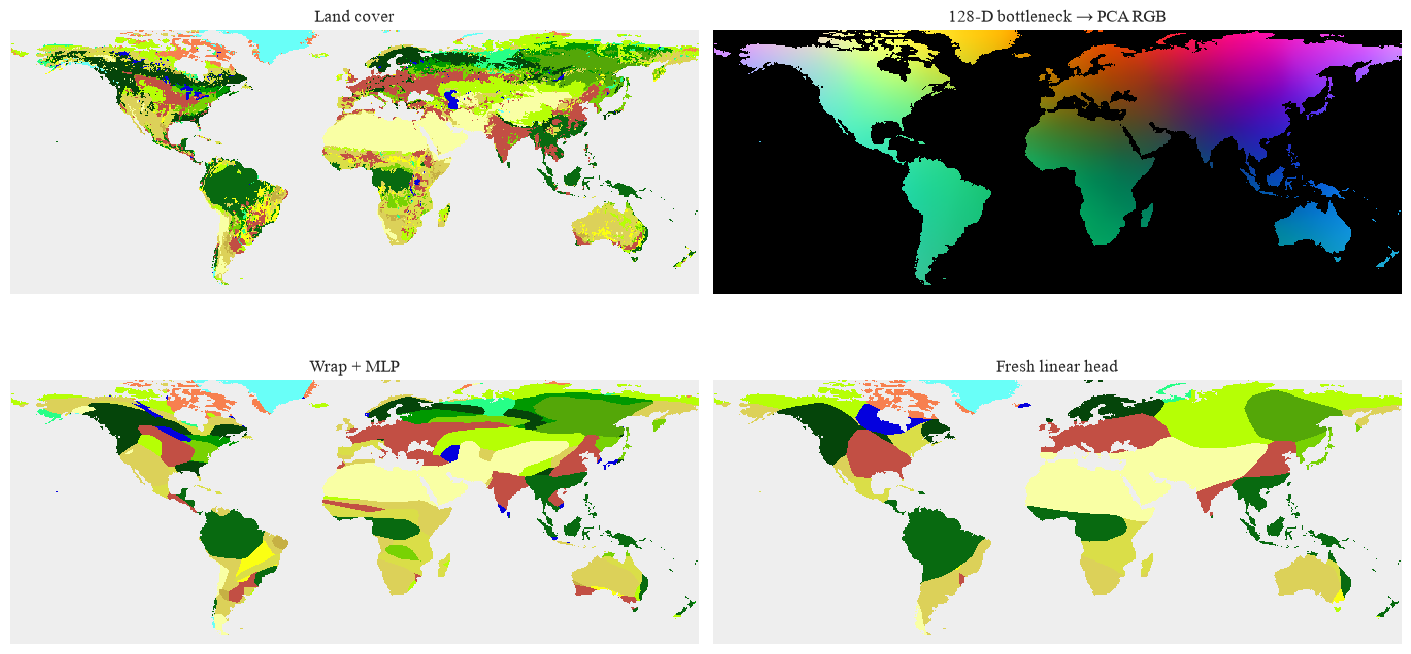

In [8]:
overview, coords = preview_grid(source, preview_height)
features = predict(encoder, torch.from_numpy(coords))
pca_features = predict(encoder, train_data.tensors[0][:65536])
rgb = pca_rgb(pca_features.numpy(), features.numpy(), overview.shape, seed)
predictions = {
    name: predict(head, features).argmax(1).numpy().reshape(overview.shape)
    for name, head in [("Wrap + MLP", model[1:]), ("Fresh linear head", linear_head)]
}
plot_comparison(
    lookup[overview],
    predictions,
    rgb,
    colors,
    class_codes,
    hidden_dim,
    output / "global_comparison.png",
)

## Export rasters

Open [inference.ipynb](inference.ipynb) to load the checkpoint and export float32 middle-layer embeddings and land-cover predictions as COGs.

The source dataset is by Demuzere, He, Martilli, and Zonato (2023), [A hybrid 100-m global land cover dataset with Local Climate Zones for WRF](https://doi.org/10.5281/zenodo.7670653), under CC BY 4.0.